# Which code? Step by step: how the tool reads the repetition code

> **In short.**
> * **The question.** `code_at(stage)` (that is, `code_of` on the program cut after that stage) prints a code: its stabilizers with their signs, logical operators and distance. How does it get them?
> * **The example.** One round of the repetition-code checks of the paper's running example: three data qubits, two ancillas measuring $X_0X_1$ (outcome $a$ = `c[0]`) and $X_1X_2$ (outcome $b$ = `c[1]`), then the correction ($Z$ on qubit 0 iff $a = 1, b = 0$; on qubit 2 iff $a = 0, b = 1$; on qubit 1 iff $a = b = 1$). The tool prints the [[3,1,1]] repetition code, with signs $(-1)^a$ and $(-1)^b$ after the round and $+$ after the correction.
> * **The steps.** (1) Rewrite the diagram into two layers. (2) Write the edges between the layers as a 0/1 matrix: rows $L$ for the spiders on the inputs, rows $M$ for the others. (3) The rows of $M$ are the $X$ stabilizers, the phases their signs; the $Z$ stabilizers are the solutions of $\binom{L}{M} z = 0$ over $\mathbb{F}_2$. (4) $k = n -$ the number of independent stabilizers. (5) Pick light generators of the same group, with as few outcomes in their signs as possible. (6) Pick the logical operators from the stabilizers alone. (7) The distance, by listing the logical operators.
> * **Checked.** Every stabilizer, with its sign, is applied to the circuit's own diagram in each of the four runs and leaves it unchanged (`stabilizes`, which compares tensors); the opposite sign does not.
> * **Library calls.** `code_layers` is the first part of `code_of`; the later steps call the $\mathbb{F}_2$ functions of `zxqec.codes.gf2` that `code_of` uses. Why each step is right is not shown here: the reading of stabilizers is Kissinger's (*Phase-free ZX diagrams are CSS codes*), $k$ and the logical operators are textbook stabilizer theory (Gottesman 1997).

In [1]:
%matplotlib inline
import numpy as np
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, Z, ConditionalGate, Measurement
from zxqec.qprogram import QProgram
from zxqec.codes import PauliString, code_layers, phase_sum, stabilizes
from zxqec.codes.gf2 import complement_basis, in_rowspace, nullspace, rank, reduce_mod, rref, solve, span
from zxqec.gpf import boolean_variables, equal_for_all_assignments, evaluate_phase
from zxqec.spacetime import draw_program

## The program

Qubits 0, 1, 2 are the data qubits; they have no initial state, so they are the program's inputs. Ancilla 3 measures $X_0X_1$ into `c[0]`, ancilla 4 measures $X_1X_2$ into `c[1]`. The correction uses PyZX's `ConditionalGate`: `ConditionalGate('c', v, Z(q), 2)` applies $Z$ to qubit $q$ when the two bits of `c` (with `c[0]` the low bit) equal $v$.

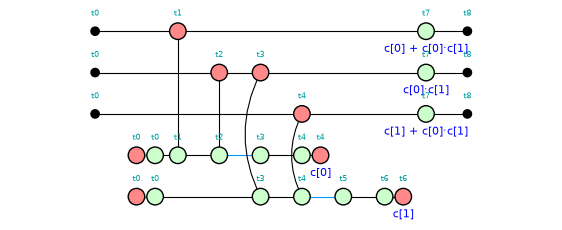

In [2]:
program = QProgram(5, bits=2, initial_states={3: '0', 4: '0'})
for name, gates in [('round', [HAD(3), HAD(4), CNOT(3, 0), CNOT(3, 1), CNOT(4, 1), CNOT(4, 2), HAD(3), HAD(4),
                               Measurement(3, result_symbol='c[0]'), Measurement(4, result_symbol='c[1]')]),
                    ('correct', [ConditionalGate('c', 1, Z(0), 2), ConditionalGate('c', 3, Z(1), 2),
                                 ConditionalGate('c', 2, Z(2), 2)])]:
    c = Circuit(5, bit_amount=2)
    for gate in gates:
        c.add_gate(gate)
    program.add_circuit(c, name=name)
draw_program(program, figsize=(7, 2.6))

What the tool prints after the round (stage 0). The rest of this notebook gets each line of it from the library's own steps; the code after the correction comes at the end.

In [3]:
code = program.code_at(0)
print(code)

[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer (-1)^(c[0])XXI
    stabilizer (-1)^(c[1])IXX
    logical X XII   logical Z ZZZ


## Step 1: two layers

`code_of` first rewrites the diagram with `reduce_gpf` into a *generalized parity form*: a layer of green (Z) spiders, a layer of red (X) spiders, edges only between the layers. `code_layers` returns that diagram and the matrices of Step 2; `code_of` starts with it. The outcomes stay variables: the diagram is the program in every run at once.

the same map as the circuit in every run: True


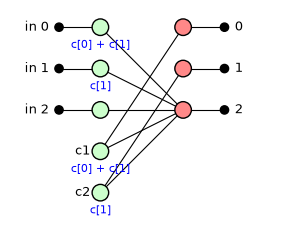

In [4]:
g = program.prefix_graph(0)
layers = code_layers(g)
names = sorted(boolean_variables(g))
print("the same map as the circuit in every run:",
      equal_for_all_assignments(g, layers.gpf.to_graph(), names, layers.gpf.constraints))
layers.draw(figsize=(3.4, 2.6))

In the picture (PyZX's drawing, with the names of `code_layers` written next to the spiders): `in 0`, `in 1`, `in 2` are the green spiders on the inputs, `c1` and `c2` the green spiders with no wire of their own, and output $j$ (right) has its own red spider. The phases are outcomes.

## Step 2: one matrix

One row per green spider, one column per output, a 1 where the green spider is joined to that output's red spider. The rows of the spiders on the inputs form $L$, the others $M$. A row of $M$ is an $X$ stabilizer and the phase of its spider is its sign: `c1` gives $(-1)^{a+b} X_0X_2$, `c2` gives $(-1)^{b} X_1X_2$.

In [5]:
print(layers.describe())

3 input(s), 2 check spider(s), 3 output(s), 0 phase gadget(s)
rows: Z-spiders; columns: outputs; 1 = wired to that output's X-spider
            0 1 2  phase
  L  in 0   0 0 1  c[0] + c[1]
     in 1   0 0 1  c[1]
     in 2   0 0 1  0
  M  c1     1 0 1  c[0] + c[1]
     c2     0 1 1  c[1]
phases of the output X-spiders: 0 0 0


The three rows of $L$ are equal: an $X$ on any input leaves on output 2. Three qubits go in and one logical qubit comes out: the round is a measurement, not an encoder, and what the tool reads is the image of the map, the space every run lands in.

Each row of $M$, with its sign, applied to the circuit's own diagram in each run (the outcomes substituted), and with the opposite sign:

In [6]:
for a in (0, 1):
    for b in (0, 1):
        run = g.substitute_variables({'c[0]': a, 'c[1]': b})
        for v, row, phase in zip(layers.check_spiders, layers.check_rows, layers.check_phases):
            sign = evaluate_phase(phase, {'c[0]': a, 'c[1]': b})
            s = PauliString.from_arrays(row, 0 * row, sign)
            print("a = {}, b = {}: {} {:6s} unchanged: {}   with the opposite sign: {}".format(
                a, b, layers.names[v], str(s), stabilizes(run, s), stabilizes(run, PauliString.from_arrays(row, 0 * row, 1 - sign))))

a = 0, b = 0: c1 +XIX   unchanged: True   with the opposite sign: False
a = 0, b = 0: c2 +IXX   unchanged: True   with the opposite sign: False
a = 0, b = 1: c1 -XIX   unchanged: True   with the opposite sign: False
a = 0, b = 1: c2 -IXX   unchanged: True   with the opposite sign: False
a = 1, b = 0: c1 -XIX   unchanged: True   with the opposite sign: False
a = 1, b = 0: c2 +IXX   unchanged: True   with the opposite sign: False
a = 1, b = 1: c1 +XIX   unchanged: True   with the opposite sign: False
a = 1, b = 1: c2 -IXX   unchanged: True   with the opposite sign: False


## Step 3: the Z stabilizers, by solving $\binom{L}{M} z = 0$

A $Z$ string is a stabilizer when every row of $L$ and of $M$ has an even number of ones on it (Kissinger). Gaussian elimination:

In [7]:
LM = np.vstack([layers.input_rows, layers.check_rows])
R, pivots, T = rref(LM, track=True)
print("(L; M):"); print(LM)
print("reduced row echelon form:"); print(R)
print("pivot columns:", pivots, "  free columns:", [c for c in range(3) if c not in pivots])
print("Z stabilizers (one per free column):", layers.z_rows().tolist())

(L; M):
[[0 0 1]
 [0 0 1]
 [0 0 1]
 [1 0 1]
 [0 1 1]]
reduced row echelon form:
[[1 0 0]
 [0 1 0]
 [0 0 1]]
pivot columns: [0, 1, 2]   free columns: []
Z stabilizers (one per free column): []


Every column is a pivot, so the only solution is $z = 0$: no $Z$ stabilizer. The row $L$ is what rules one out. Without it, $Mz = 0$ has the solution $ZZZ$; it meets each input row once, an odd number of times, and it changes the map: it is the logical $Z$ (Step 6).

In [8]:
zzz = nullspace(layers.check_rows)[0]
print("solutions of M z = 0:", [str(PauliString.from_arrays(0 * zzz, zzz))], "  meets the rows of L:", (layers.input_rows @ zzz).tolist())
print("leaves the circuit unchanged (run a = b = 0):",
      stabilizes(g.substitute_variables({'c[0]': 0, 'c[1]': 0}), PauliString.from_arrays(0 * zzz, zzz)))

solutions of M z = 0: ['+ZZZ']   meets the rows of L: [1, 1, 1]
leaves the circuit unchanged (run a = b = 0): False


## Step 4: how many logical qubits

$k = n -$ (number of independent stabilizers) $= 3 - 2 = 1$.

In [9]:
print("independent X stabilizers:", rank(layers.check_rows), "  Z stabilizers:", len(layers.z_rows()),
      "  k =", 3 - rank(layers.check_rows) - len(layers.z_rows()), "  code_of:", code.k)

independent X stabilizers: 2   Z stabilizers: 0   k = 1   code_of: 1


## Step 5: the generators it prints

The group of $X$ stabilizers is all sums of rows of $M$, $2^2 = 4$ strings; the sign of a sum is the sum of the signs. Which two generators to print is a choice. `code_of` sorts the group by weight, then by the number of outcomes in the sign, then by support, and keeps each string independent of those kept so far. All three strings have weight 2; $X_0X_2$ has two outcomes in its sign, so the two kept are $X_0X_1$ and $X_1X_2$: the two operators the program measured, each with its own outcome as its sign.

In [10]:
for v in span(layers.check_rows)[1:]:
    combination = solve(layers.check_rows.T, v)
    sign = phase_sum([phase for phase, c_ in zip(layers.check_phases, combination) if c_])
    print("{:18s} = {:9s} weight {}, outcomes in the sign: {}".format(
        str(PauliString.from_arrays(v, 0 * v, sign)),
        " + ".join(layers.names[s] for s, c_ in zip(layers.check_spiders, combination) if c_),
        v.sum(), len(sign.free_vars()) if hasattr(sign, 'free_vars') else 0))
print("printed:", [str(s) for s in code.stabilizers])

(-1)^(c[0])XXI     = c1 + c2   weight 2, outcomes in the sign: 1
(-1)^(c[0] + c[1])XIX = c1        weight 2, outcomes in the sign: 2
(-1)^(c[1])IXX     = c2        weight 2, outcomes in the sign: 1
printed: ['(-1)^(c[0])XXI', '(-1)^(c[1])IXX']


## Step 6: the logical operators, from the stabilizers alone

They are chosen from the stabilizers only, not read from $L$, so that two diagrams of the same code get the same names.

**Logical $X$.** The $X$ strings that commute with every $Z$ stabilizer (here all of them: there is no $Z$ stabilizer), reduced modulo the $X$ stabilizers; one class is left, so $k = 1$; its lightest string, ties by support.

In [11]:
SX, SZ = code.sx, code.sz
WX = nullspace(SZ)
RX, PX, _ = rref(SX)
print("X strings that commute with every Z stabilizer, a basis:", [str(PauliString.from_arrays(v, 0 * v)) for v in WX])
LX = complement_basis(SX, WX)
print("classes left modulo the X stabilizers:", len(LX), "  representative:", PauliString.from_arrays(LX[0], 0 * LX[0]))
print("its class, lightest first:", [str(PauliString.from_arrays(v, 0 * v)) for v in span(np.vstack([SX, LX]))
                                     if not in_rowspace(v, RX, PX)])
print("logical X printed:", code.logical_x[0])

X strings that commute with every Z stabilizer, a basis: ['+XII', '+IXI', '+IIX']
classes left modulo the X stabilizers: 1   representative: +IIX
its class, lightest first: ['+XII', '+IXI', '+IIX', '+XXX']
logical X printed: +XII


**Logical $Z$.** A $Z$ string that commutes with every $X$ stabilizer and meets the logical $X$ an odd number of times.

In [12]:
WZ = nullspace(SX)
print("Z strings that commute with every X stabilizer, a basis:", [str(PauliString.from_arrays(0 * w, w)) for w in WZ])
print("how often each meets the logical X, mod 2:", ((LX @ WZ.T) % 2)[0])
print("logical Z printed:", code.logical_z[0])

Z strings that commute with every X stabilizer, a basis: ['+ZZZ']
how often each meets the logical X, mod 2: [1]
logical Z printed: +ZZZ


## Step 7: the distance

List the $X$ strings that commute with every $Z$ stabilizer and the $Z$ strings that commute with every $X$ stabilizer; those outside the stabilizer group are logical operators, and the distance is the weight of the lightest one.

In [13]:
for v in span(WX):
    print("  ", PauliString.from_arrays(v, 0 * v), " weight", v.sum(), " ", "stabilizer" if in_rowspace(v, RX, PX) else "logical")
for w in span(WZ):
    print("  ", PauliString.from_arrays(0 * w, w), " weight", w.sum(), " ", "stabilizer" if not w.any() else "logical")
print("lightest logical X:", min(int(v.sum()) for v in span(WX) if not in_rowspace(v, RX, PX)),
      "  lightest logical Z:", min(int(w.sum()) for w in span(WZ) if w.any()), "  distance printed:", code.distance)

   +III  weight 0   stabilizer
   +XII  weight 1   logical
   +IXI  weight 1   logical
   +IIX  weight 1   logical
   +XXI  weight 2   stabilizer
   +XIX  weight 2   stabilizer
   +IXX  weight 2   stabilizer
   +XXX  weight 3   logical
   +III  weight 0   stabilizer
   +ZZZ  weight 3   logical
lightest logical X: 1   lightest logical Z: 3   distance printed: 1


A single $X$ is a logical operator, so the distance is 1; against $Z$ errors alone the code has distance 3. The repetition code with $X$ checks protects against $Z$ errors only, as the error table of the running example shows.

## After the correction

The same reading of the program cut after the correction (stage 1). The rows are the same; the phases of `c1` and `c2` are now 0, so both signs are $+$ in every run, and the order by support picks $X_0X_1$ and $X_0X_2$. The correction itself sits on the input spiders, where it does not change the code: the condition $a(1-b)$ is `c[0] + c[0]⋅c[1]`.

In [14]:
after = code_layers(program.prefix_graph(1))
print(after.describe())
print()
print(program.code_at(1))

3 input(s), 2 check spider(s), 3 output(s), 0 phase gadget(s)
rows: Z-spiders; columns: outputs; 1 = wired to that output's X-spider
            0 1 2  phase
  L  in 0   0 0 1  c[0] + c[0]⋅c[1]
     in 1   0 0 1  c[0]⋅c[1]
     in 2   0 0 1  c[0]⋅c[1] + c[1]
  M  c1     1 0 1  0
     c2     0 1 1  0
phases of the output X-spiders: 0 0 0

[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer +XXI
    stabilizer +XIX
    logical X XII   logical Z ZZZ
